# Démo 1 : compression d'image par SVD avec Spark MLlib

**Idée :** une image en niveaux de gris est une matrice $A$ ($m \times n$) de pixels.
La SVD donne $A = U \Sigma V^T$. En ne gardant que les $k$ plus grandes valeurs
singulières, on obtient $A_k = U_k \Sigma_k V_k^T$, **la meilleure approximation
de rang $k$** de $A$ (théorème d'Eckart–Young).

Stockage : $k(m + n + 1)$ nombres au lieu de $m \times n$.

API utilisée : `pyspark.mllib.linalg.distributed.IndexedRowMatrix.computeSVD`
(implémentation **RDD** : la SVD n'existe pas dans l'API Pipeline `spark.ml`).

In [1]:
import os

import matplotlib.pyplot as plt
import numpy as np
from skimage import color, data

from spark_utils import cache_jvm, get_spark
from pyspark.mllib.linalg import Vectors
from pyspark.mllib.linalg.distributed import IndexedRow, IndexedRowMatrix

os.makedirs("figures", exist_ok=True)
spark = get_spark("SVD-compression-image")
sc = spark.sparkContext

## 1. Charger l'image et la transformer en matrice distribuée
Chaque ligne de pixels devient une `IndexedRow` (index de ligne + vecteur dense).
On utilise `IndexedRowMatrix` plutôt que `RowMatrix` pour **garder l'ordre des lignes**
(une `RowMatrix` n'a pas d'index : l'ordre de ses lignes n'est pas garanti).

In [2]:
img = color.rgb2gray(data.astronaut())  # 512 x 512, valeurs dans [0, 1]
m, n = img.shape
print(f"Image : {m} x {n} = {m * n:,} pixels")

rows = sc.parallelize(
    [IndexedRow(i, Vectors.dense(img[i])) for i in range(m)], numSlices=8
)
A = cache_jvm(IndexedRowMatrix(rows))  # SVD itérative -> on garde la matrice en mémoire
print("Matrice distribuée :", A.numRows(), "x", A.numCols())

Image : 512 x 512 = 262,144 pixels


Matrice distribuée : 512 x 512


## 2. Calculer la SVD tronquée (k = 100) avec Spark
`computeSVD(k, computeU=True)` renvoie :
- `U` : `IndexedRowMatrix` distribuée ($m \times k$)
- `s` : vecteur local des $k$ valeurs singulières (décroissantes)
- `V` : matrice locale ($n \times k$)

In [3]:
K_MAX = 100
svd = A.computeSVD(K_MAX, computeU=True)

s = svd.s.toArray()
V = svd.V.toArray()
U_rows = sorted(svd.U.rows.map(lambda r: (r.index, r.vector.toArray())).collect())
U = np.vstack([v for _, v in U_rows])
print("U :", U.shape, " s :", s.shape, " V :", V.shape)
print("5 premières valeurs singulières :", np.round(s[:5], 2))

U : (512, 100)  s : (100,)  V : (512, 100)
5 premières valeurs singulières : [241.26  71.12  45.98  38.01  31.25]


## 3. Reconstruire l'image avec k composantes
Comme les composantes de la SVD sont emboîtées, une seule SVD (k = 100) suffit :
on tronque ensuite à k = 5, 20, 50, 100.

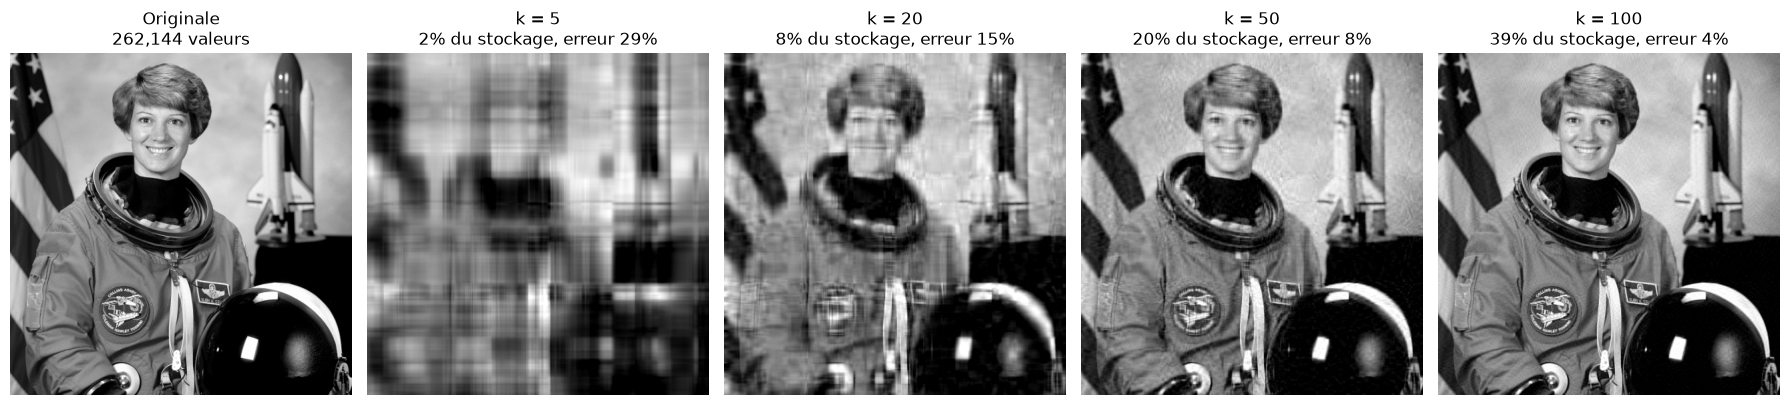

   k |  stockage |  ratio |  énergie | erreur rel.
   5 |     5,125 |   2.0% |   91.49% |      29.10%
  20 |    20,500 |   7.8% |   97.83% |      14.53%
  50 |    51,250 |  19.6% |   99.35% |       7.94%
 100 |   102,500 |  39.1% |   99.82% |       4.19%


In [4]:
total_energy = np.sum(img ** 2)  # = somme de toutes les valeurs singulières au carré


def reconstruct(k):
    return (U[:, :k] * s[:k]) @ V[:, :k].T


ks = [5, 20, 50, 100]
fig, axes = plt.subplots(1, len(ks) + 1, figsize=(18, 4.2))
axes[0].imshow(img, cmap="gray")
axes[0].set_title(f"Originale\n{m * n:,} valeurs")
results = []
for ax, k in zip(axes[1:], ks):
    Ak = np.clip(reconstruct(k), 0, 1)
    stockage = k * (m + n + 1)
    ratio = stockage / (m * n)
    energie = np.sum(s[:k] ** 2) / total_energy
    erreur = np.linalg.norm(img - Ak) / np.linalg.norm(img)
    results.append((k, stockage, ratio, energie, erreur))
    ax.imshow(Ak, cmap="gray")
    ax.set_title(f"k = {k}\n{ratio:.0%} du stockage, erreur {erreur:.0%}")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.savefig("figures/compression_reconstructions.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"{'k':>4} | {'stockage':>9} | {'ratio':>6} | {'énergie':>8} | {'erreur rel.':>11}")
for k, st, r, e, err in results:
    print(f"{k:>4} | {st:>9,} | {r:>6.1%} | {e:>8.2%} | {err:>11.2%}")

## 4. Spectre des valeurs singulières
Les valeurs singulières décroissent très vite : quelques composantes
concentrent l'essentiel de l'« énergie » (la norme de Frobenius au carré) de l'image.

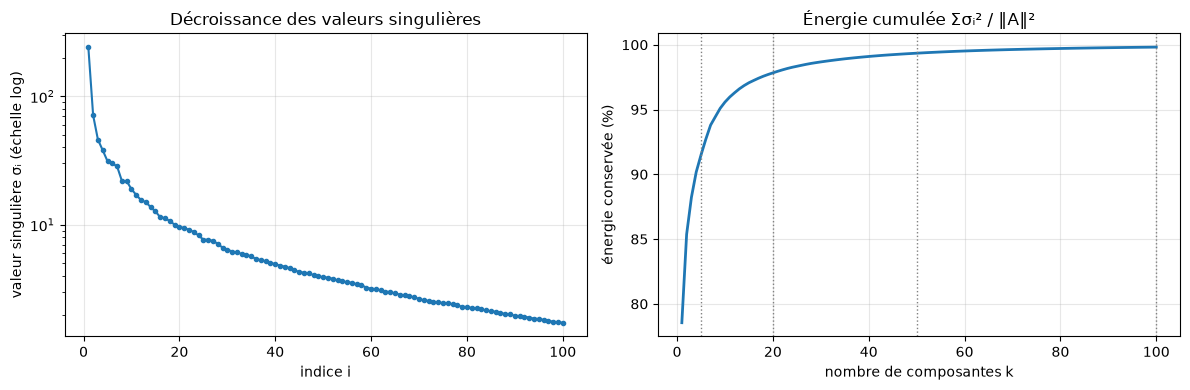

In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.semilogy(np.arange(1, K_MAX + 1), s, "o-", ms=3)
ax1.set_xlabel("indice i")
ax1.set_ylabel("valeur singulière σᵢ (échelle log)")
ax1.set_title("Décroissance des valeurs singulières")
ax1.grid(alpha=0.3)

energy = np.cumsum(s ** 2) / total_energy
ax2.plot(np.arange(1, K_MAX + 1), energy * 100, "-", lw=2)
for k in ks:
    ax2.axvline(k, color="grey", ls=":", lw=1)
ax2.set_xlabel("nombre de composantes k")
ax2.set_ylabel("énergie conservée (%)")
ax2.set_title("Énergie cumulée Σσᵢ² / ‖A‖²")
ax2.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("figures/compression_spectre.png", dpi=150, bbox_inches="tight")
plt.show()

In [6]:
spark.stop()